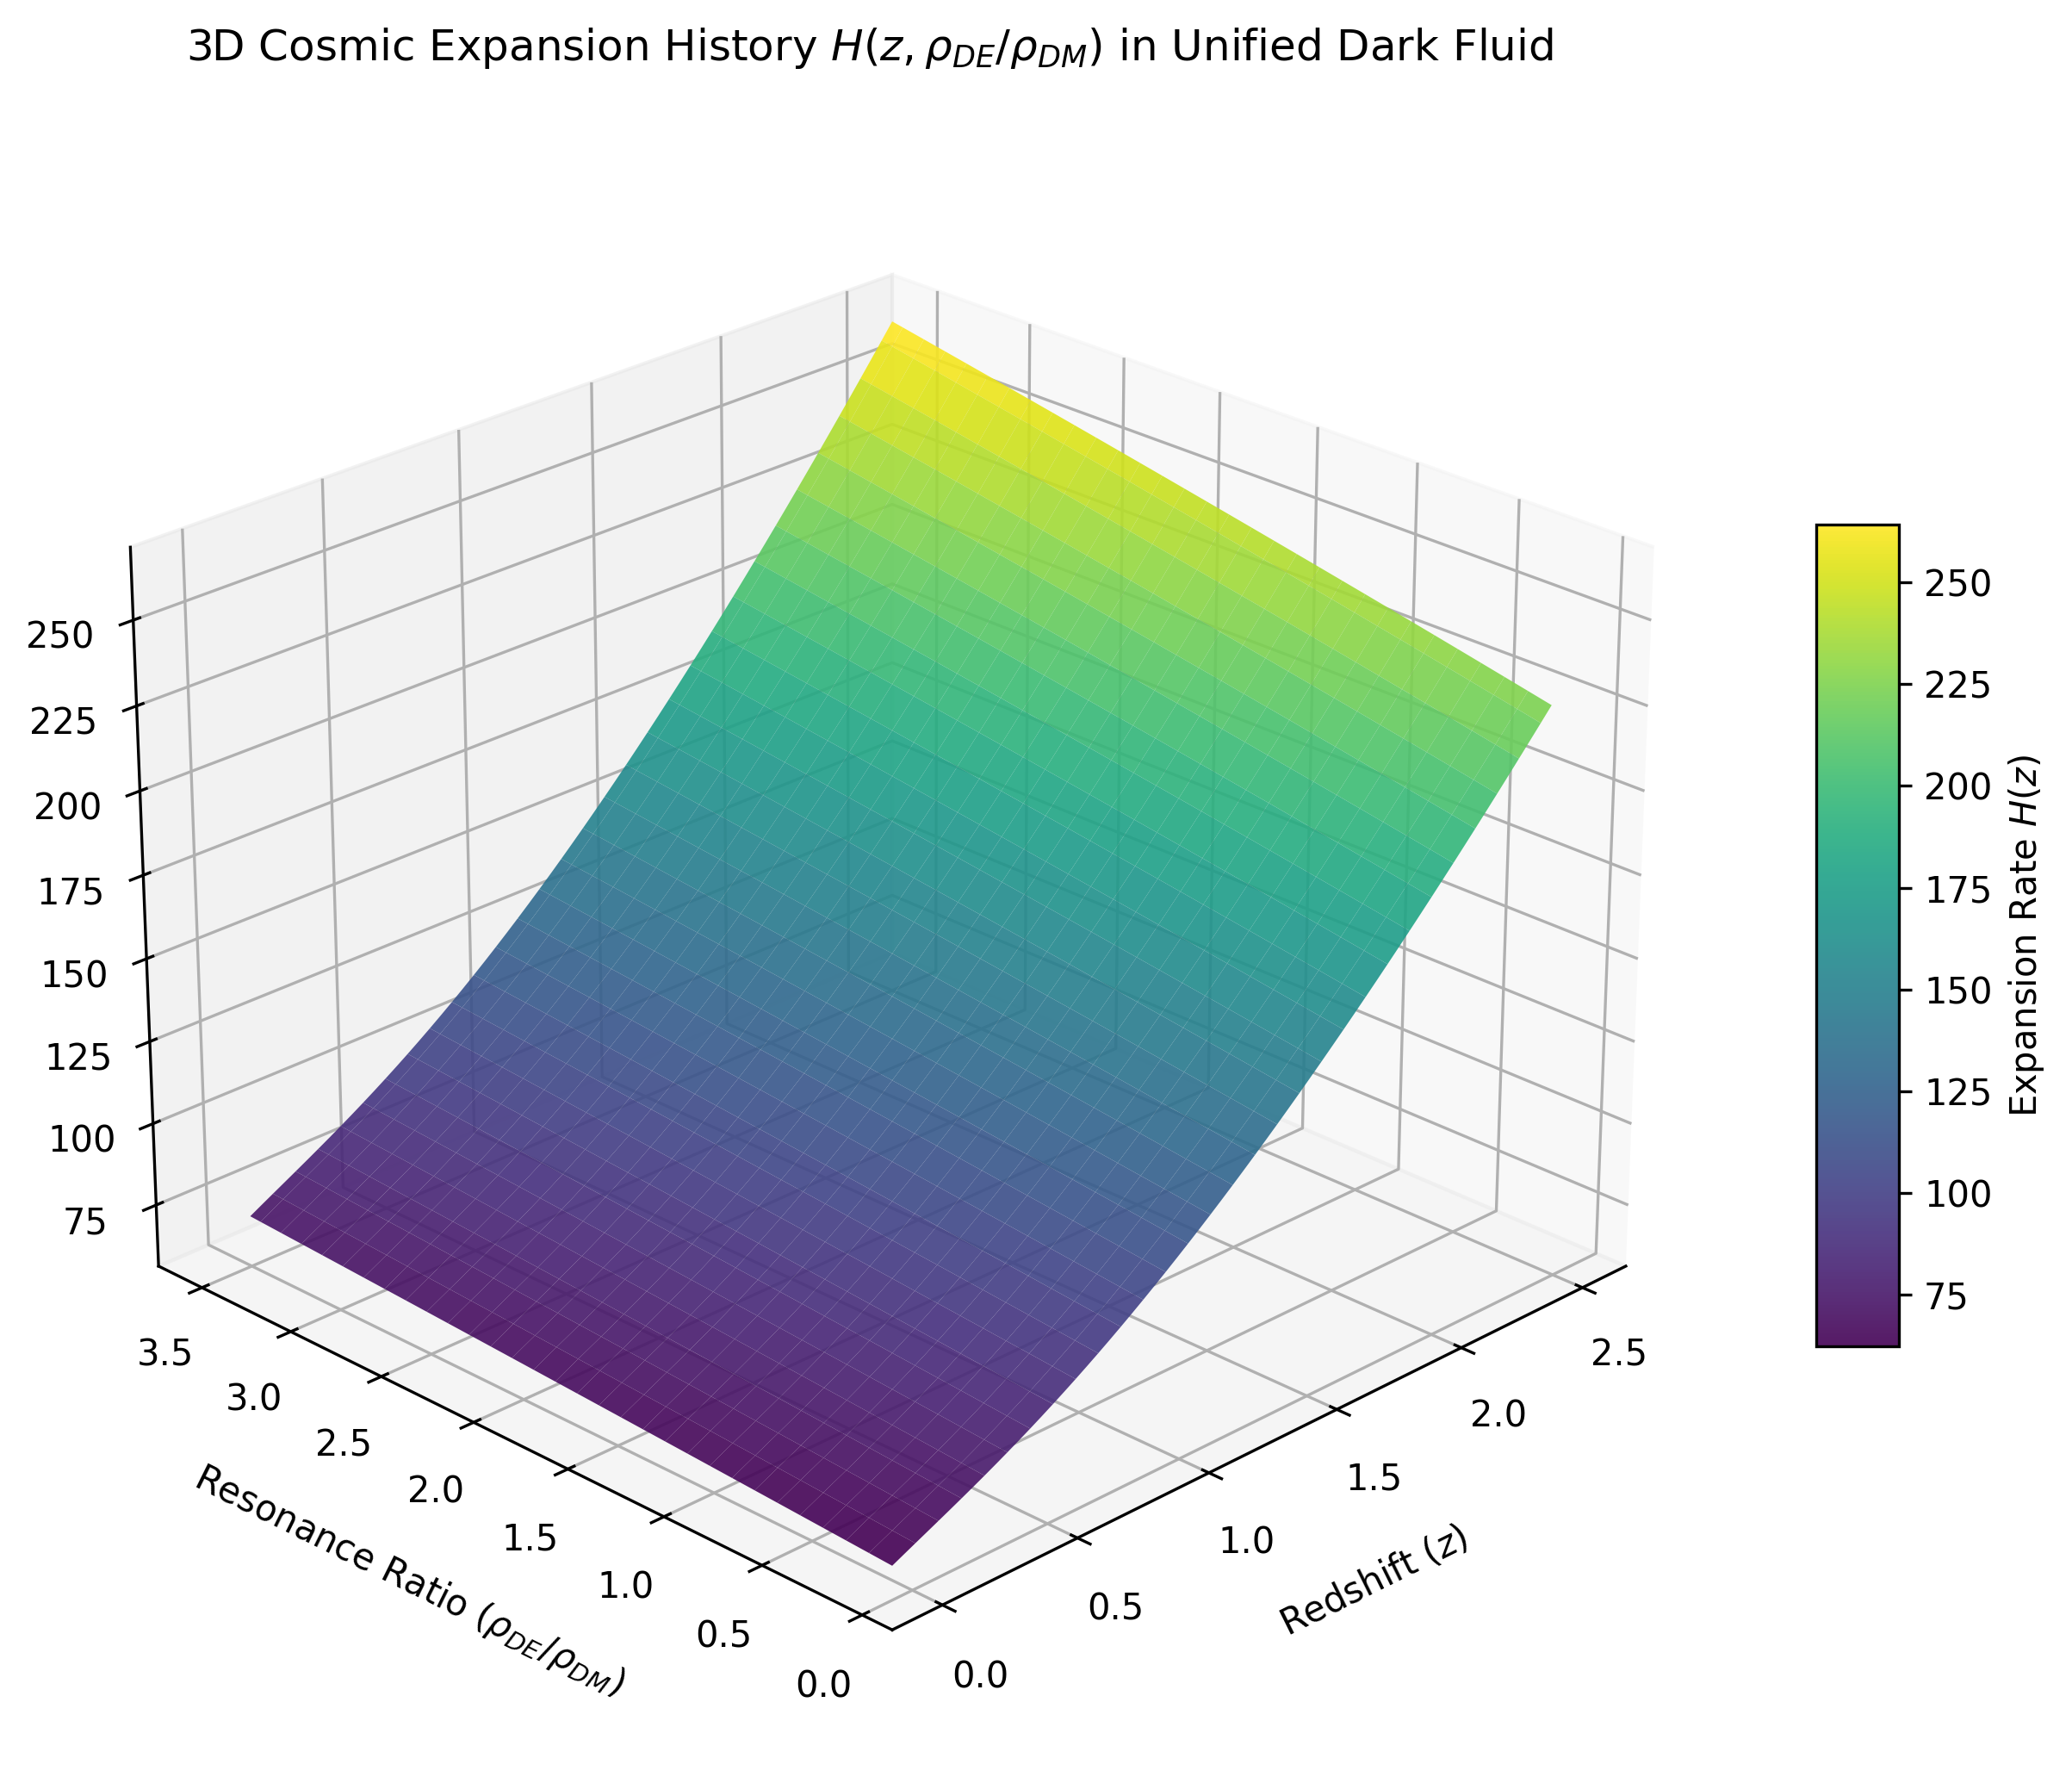

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# الثوابت الكونية الأساسية حسب قيود البحث
H0_planck = 67.4  # km/s/Mpc
Omega_m = 0.315
Omega_de0 = 0.685
beta = 0.12       # ثابت الاقتران الرنيني-التوسعي

# شبكة البيانات: الانزياح الأحمر z ونسبة الرنين المحلي (rho_DE / rho_DM)
z = np.linspace(0.0, 2.5, 60)
ratio_de_dm = np.linspace(0.1, 3.5, 60)
Z, R = np.meshgrid(z, ratio_de_dm)

# معادلة التوسع المعدلة بناءً على تضخم الطول الموجي الرنيني (المعادلة 12)
# في الفراغات (R مرتفع) يزداد الضغط الهيدروليكي السالب ويرتفع H(z) المحلي
w0, wa = -0.82, -0.75  # قيم DESI DR1 المتوافقة مع النموذج
f_de = (1 + Z)**(3 * (1 + w0 + wa)) * np.exp(-3 * wa * Z / (1 + Z))
resonance_boost = np.sqrt(1 + beta * R) / np.sqrt(1 + beta * 2.17)

H_unified = H0_planck * np.sqrt(Omega_m * (1 + Z)**3 + Omega_de0 * f_de) * resonance_boost

# الرسم الثلاثي الأبعاد
fig = plt.figure(figsize=(10, 7), dpi=300)
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(Z, R, H_unified, cmap='viridis', edgecolor='none', alpha=0.9)

ax.set_title('3D Cosmic Expansion History $H(z, \\rho_{DE}/\\rho_{DM})$ in Unified Dark Fluid', fontsize=12, pad=15)
ax.set_xlabel('Redshift ($z$)', fontsize=10, labelpad=10)
ax.set_ylabel('Resonance Ratio ($\\rho_{DE} / \\rho_{DM}$)', fontsize=10, labelpad=10)
ax.set_zlabel('$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]', fontsize=10, labelpad=10)
fig.colorbar(surf, shrink=0.5, aspect=10, label='Expansion Rate $H(z)$')
ax.view_init(elev=25, azim=-135)

plt.tight_layout()
plt.savefig('sim1_3d_hubble_expansion.png', dpi=300)
plt.show()